# ANA500 Micro-Project 4
Charles Ayuk | November 7, 2026

Source: supplied airline.csv. Repository: [https://github.com/ChalesManyang/ANA500-Micro-Projects](https://github.com/ChalesManyang/ANA500-Micro-Projects)

Run cells in order. Python 3.11+ and requirements.txt are recommended.


## Acquire: load the supplied file and inspect its structure.

In [1]:
# Acquire: load the supplied file and inspect its structure.
from pathlib import Path
import numpy as np
import pandas as pd
# Keep airline.csv beside this notebook, or edit DATA_PATH below.
DATA_PATH = Path('airline.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('../airline.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('../../upload/airline.csv')
raw = pd.read_csv(DATA_PATH)
print('Raw rows and columns:', raw.shape)
print(raw.dtypes.to_string())
print('Missing values:', raw.isna().sum()[raw.isna().sum() > 0].to_dict())



Raw rows and columns: (129880, 25)
Unnamed: 0                             int64
id                                     int64
Gender                                object
Customer Type                         object
Age                                    int64
Type of Travel                        object
Class                                 object
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online booking                 int64
Gate location                          int64
Food and drink                         int64
Online boarding                        int64
Seat comfort                           int64
Inflight entertainment                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Inflight service                       int64
Cleanliness         

## Prepare: preserve raw data and create an independent working copy.

In [2]:
# Prepare: preserve raw data and create an independent working copy.
df = raw.copy()
for col in df.select_dtypes(include='object'):
    df[col] = df[col].str.strip()
# The exported row counter is not a passenger attribute.
df = df.drop(columns=[c for c in df if c.startswith('Unnamed:')])
# Check complete duplicate records before considering any removal.
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('Repeated passenger IDs:', int(df['id'].duplicated().sum()))
# Preserve valid zero ratings; their meaning is undocumented in this upload.
# Never assume zero means missing without a data dictionary.
ratings = list(df.loc[:, 'Inflight wifi service':'Cleanliness'].columns)
assert df[ratings].apply(lambda s: s.between(0, 5).all()).all()
assert df['Age'].between(0, 120).all()
assert (df[['Flight Distance', 'Departure Delay in Minutes']].to_numpy() >= 0).all()
print('Rating range:', int(df[ratings].min().min()), int(df[ratings].max().max()))
# Keep missing arrival delays as NaN. Project 4 excludes them as unknown targets.
print(df[['Age','Flight Distance','Departure Delay in Minutes',
          'Arrival Delay in Minutes']].describe().round(2).to_string())
print('Satisfied share (%):', round(df['satisfaction'].eq('satisfied').mean()*100, 2))
# NumPy arrays support explicit missing-value-aware numerical summaries.
arrivals = df['Arrival Delay in Minutes'].to_numpy(dtype=float)
print('Arrival mean / median:', np.nanmean(arrivals), np.nanmedian(arrivals))
print('Known arrival values:', int(np.isfinite(arrivals).sum()))
print('Preparation complete. No missing targets were filled.')



Exact duplicate rows: 0
Repeated passenger IDs: 0
Rating range: 0 5
             Age  Flight Distance  Departure Delay in Minutes  Arrival Delay in Minutes
count  129880.00        129880.00                   129880.00                 129487.00
mean       39.43          1190.32                       14.71                     15.09
std        15.12           997.45                       38.07                     38.47
min         7.00            31.00                        0.00                      0.00
25%        27.00           414.00                        0.00                      0.00
50%        40.00           844.00                        0.00                      0.00
75%        51.00          1744.00                       12.00                     13.00
max        85.00          4983.00                     1592.00                   1584.00
Satisfied share (%): 43.45
Arrival mean / median: 15.09112883918849 0.0
Known arrival values: 129487
Preparation complete. No missing target

## Prepare: define a continuous outcome and predictors available at departure.

In [3]:
# Prepare: define a continuous outcome and predictors available at departure.
# Satisfaction and post-flight service ratings are excluded to avoid leakage.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
import copy
threadpool_limits(limits=1)
model_df = df.dropna(subset=['Arrival Delay in Minutes']).copy()
num = ['Departure Delay in Minutes','Flight Distance','Age']
cat = ['Gender','Customer Type','Type of Travel','Class']
X = model_df[num+cat]
y = model_df['Arrival Delay in Minutes'].to_numpy()
# Split before fitting preprocessing. Reserve test data for the final evaluation.
train_i, other_i = train_test_split(np.arange(len(y)),test_size=.30,random_state=42)
val_i, test_i = train_test_split(other_i,test_size=.50,random_state=42)
prep = ColumnTransformer([
    ('numeric',StandardScaler(),num),
    ('category',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat)])
Xt=prep.fit_transform(X.iloc[train_i]); Xv=prep.transform(X.iloc[val_i])
Xe=prep.transform(X.iloc[test_i])
ys=StandardScaler().fit(y[train_i].reshape(-1,1))
yt=ys.transform(y[train_i].reshape(-1,1)).ravel()
print('Train / validation / test:', len(train_i),len(val_i),len(test_i))
print('Encoded predictor count:', Xt.shape[1])



Train / validation / test: 90640 19423 19424
Encoded predictor count: 12


## Analyze: train two deep feedforward neural networks with validation stopping.

In [4]:
# Analyze: train two deep feedforward neural networks with validation stopping.
# Three hidden layers learn nonlinear relationships in independent tabular rows.
# Recurrent networks require a meaningful sequence; none is supplied here.
# partial_fit performs one epoch. Save the weights with the best validation RMSE.
candidates=[]; histories=[]
for architecture in [(32,16,8),(64,32,16)]:
    nn=MLPRegressor(hidden_layer_sizes=architecture,activation='relu',solver='adam',
        batch_size=256,learning_rate_init=.001,alpha=.01,random_state=42,
        max_iter=1,shuffle=True)
    best_rmse=np.inf; stale=0; best_model=None; history=[]
    for epoch in range(1,81):
        nn.partial_fit(Xt,yt)
        pred=ys.inverse_transform(nn.predict(Xv).reshape(-1,1)).ravel()
        # Arrival delays in this dataset are nonnegative; apply the same rule at test.
        pred=np.maximum(pred,0)
        rmse=float(np.sqrt(mean_squared_error(y[val_i],pred)))
        history.append(rmse)
        if rmse < best_rmse-.001:
            best_rmse=rmse; best_model=copy.deepcopy(nn); best_epoch=epoch; stale=0
        else: stale+=1
        if stale>=8: break
    candidates.append((best_rmse,best_model,architecture,best_epoch))
    histories.append(history)
    print('Architecture / best epoch / validation RMSE:',architecture,best_epoch,best_rmse)
best_rmse, best_nn, best_arch, best_epoch=min(candidates,key=lambda z:z[0])
print('Selected by validation RMSE:',best_arch)



Architecture / best epoch / validation RMSE: (32, 16, 8) 6 9.761551895096188
Architecture / best epoch / validation RMSE: (64, 32, 16) 1 9.813766438368294
Selected by validation RMSE: (32, 16, 8)


## Report: evaluate the frozen selected network once on held-out test rows.

                              MAE     RMSE      R2
Model                                             
Training mean             20.7593  39.1626 -0.0004
Departure equals arrival   5.0403  10.0751  0.9338
Linear regression          5.3487  10.0287  0.9344
Deep neural network        5.5960   9.9324  0.9357
Test outcomes >=60 min: 1504
Training mean MAE for >=60 min: 105.44435644401047
Departure equals arrival MAE for >=60 min: 15.46808510638298
Linear regression MAE for >=60 min: 15.272792754870357
Deep neural network MAE for >=60 min: 16.532419615729832


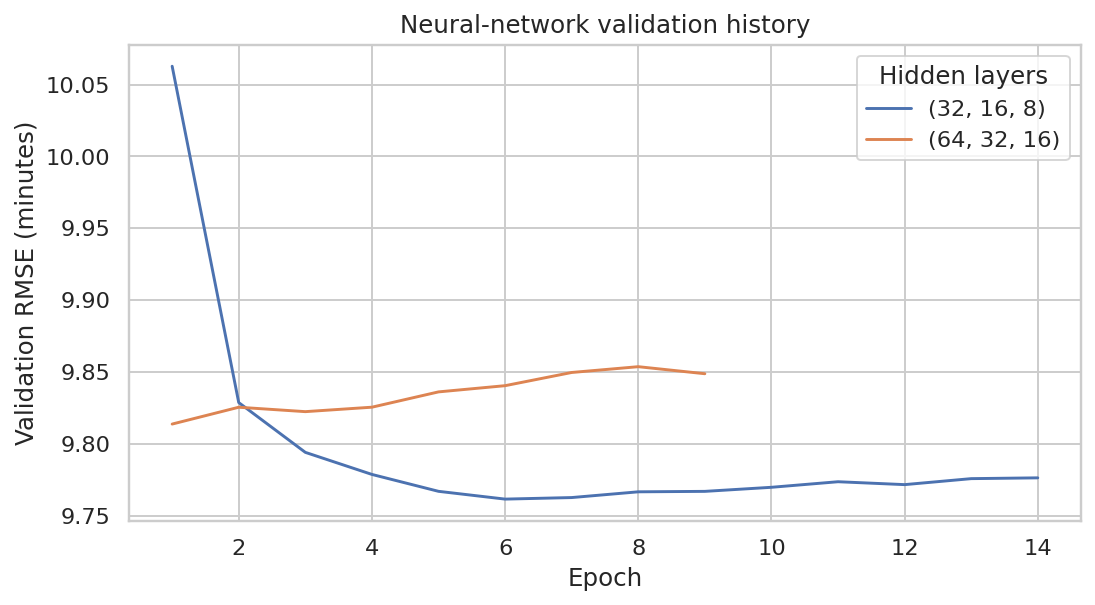

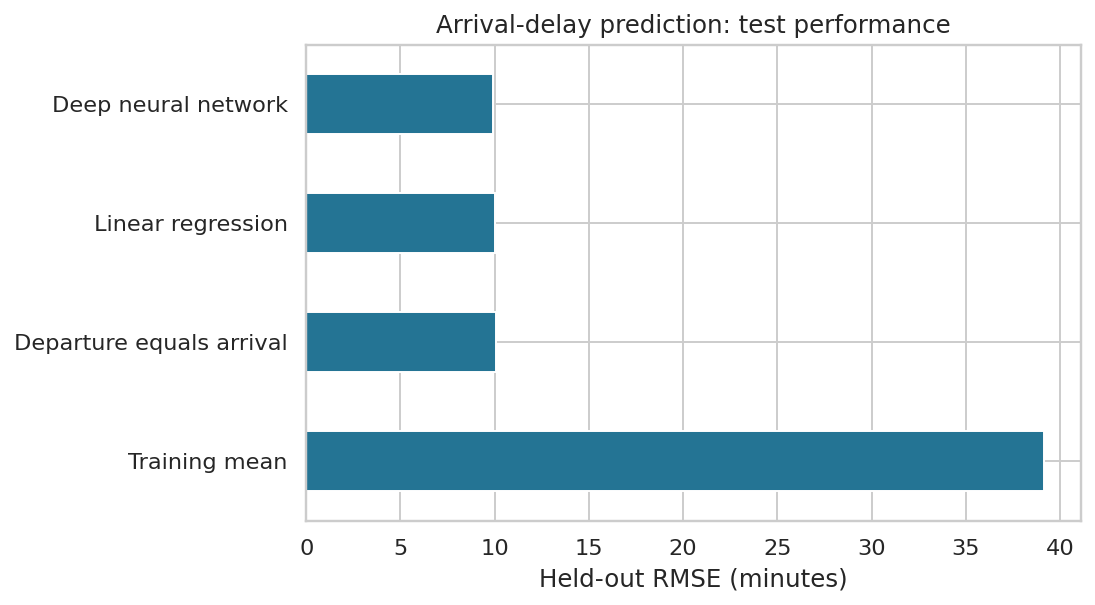

In [5]:
# Report: evaluate the frozen selected network once on held-out test rows.
linear=LinearRegression().fit(Xt,y[train_i])
predictions={
 'Training mean':np.repeat(y[train_i].mean(),len(test_i)),
 'Departure equals arrival':X.iloc[test_i]['Departure Delay in Minutes'].to_numpy(),
 'Linear regression':np.maximum(linear.predict(Xe),0),
 'Deep neural network':np.maximum(ys.inverse_transform(best_nn.predict(Xe).reshape(-1,1)).ravel(),0)}
results=[]
for name,pred in predictions.items():
    results.append({'Model':name,'MAE':mean_absolute_error(y[test_i],pred),
       'RMSE':np.sqrt(mean_squared_error(y[test_i],pred)),'R2':r2_score(y[test_i],pred)})
metrics=pd.DataFrame(results).set_index('Model')
print(metrics.round(4).to_string())
# Extreme-delay errors help assess whether good overall metrics hide tail failures.
mask=y[test_i]>=60
print('Test outcomes >=60 min:',int(mask.sum()))
for name,pred in predictions.items():
    print(name,'MAE for >=60 min:',mean_absolute_error(y[test_i][mask],pred[mask]))
fig,ax=plt.subplots(figsize=(8,4.5))
for candidate,history in zip(candidates,histories):
    ax.plot(np.arange(1,len(history)+1),history,label=str(candidate[2]))
ax.set(xlabel='Epoch',ylabel='Validation RMSE (minutes)',title='Neural-network validation history')
ax.legend(title='Hidden layers');fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,4.5))
metrics['RMSE'].plot.barh(ax=ax,color='#247494')
ax.set(xlabel='Held-out RMSE (minutes)',ylabel='',title='Arrival-delay prediction: test performance')
fig.tight_layout();plt.show()



## Act: connect predictive performance to an operational decision.

In [6]:
# Act: connect predictive performance to an operational decision.
print('Use this model only as a retrospective prototype for updates after departure.')
print('Compare the network with linear regression before choosing an operational model.')
print('Pilot on dated flight-level records and evaluate temporal holdout performance.')
print('Validate error by route, flight and delay severity before customer-facing use.')
print('This survey has no dates, routes, weather or flight IDs; random splits cannot test future performance.')
print('Rows may share a flight, so passenger-level random splitting may overstate generalization.')
print('Prediction does not demonstrate that any feature causes delay.')


Use this model only as a retrospective prototype for updates after departure.
Compare the network with linear regression before choosing an operational model.
Pilot on dated flight-level records and evaluate temporal holdout performance.
Validate error by route, flight and delay severity before customer-facing use.
This survey has no dates, routes, weather or flight IDs; random splits cannot test future performance.
Rows may share a flight, so passenger-level random splitting may overstate generalization.
Prediction does not demonstrate that any feature causes delay.
